In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# pip install kagglehub

In [3]:
import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("wordsforthewise/lending-club")

# print("Path to dataset files:", path)

C:\Users\riyas\da_projects\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [24]:
import os
path = "C:\\Users\\riyas\\.cache\\kagglehub\\datasets\\wordsforthewise\\lending-club\\versions\\3"
print(os.walk(path))
for root, dirs, files in os.walk(path):
    for file in files:
        print(file)

<generator object walk at 0x000001ACAA4ED740>
accepted_2007_to_2018Q4.csv.gz
rejected_2007_to_2018Q4.csv.gz
accepted_2007_to_2018Q4.csv
rejected_2007_to_2018Q4.csv


In [26]:
cols = [
    'loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'emp_length',
    'home_ownership', 'annual_inc', 'verification_status', 'issue_d',
    'loan_status', 'purpose', 'dti', 'delinq_2yrs', 'open_acc', 'pub_rec',
    'revol_bal', 'revol_util', 'total_acc',
    'total_pymnt'          # money actually received (used for profit only)
]
df = pd.read_csv("C:\\Users\\riyas\\OneDrive\\Desktop\\Analyst&Dev\\Data Analysis Projects & Resources\\Loan Approval\\accepted_2007_to_2018Q4.csv",
                usecols =  cols,
                 low_memory = False
                )


In [27]:
df.head()

,loan_amnt,term,int_rate,installment,grade,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,dti,delinq_2yrs,open_acc,pub_rec,revol_bal,revol_util,total_acc,total_pymnt
0,3600.0,36 months,13.99,123.03,C,10+ years,MORTGAGE,55000.0,Not Verified,Dec-2015,Fully Paid,debt_consolidation,5.91,0.0,7.0,0.0,2765.0,29.7,13.0,4421.723917
1,24700.0,36 months,11.99,820.28,C,10+ years,MORTGAGE,65000.0,Not Verified,Dec-2015,Fully Paid,small_business,16.06,1.0,22.0,0.0,21470.0,19.2,38.0,25679.660000
2,20000.0,60 months,10.78,432.66,B,10+ years,MORTGAGE,63000.0,Not Verified,Dec-2015,Fully Paid,home_improvement,10.78,0.0,6.0,0.0,7869.0,56.2,18.0,22705.924294
3,35000.0,60 months,14.85,829.90,C,10+ years,MORTGAGE,110000.0,Source Verified,Dec-2015,Current,debt_consolidation,17.06,0.0,13.0,0.0,7802.0,11.6,17.0,31464.010000
4,10400.0,60 months,22.45,289.91,F,3 years,MORTGAGE,104433.0,Source Verified,Dec-2015,Fully Paid,major_purchase,25.37,1.0,12.0,0.0,21929.0,64.5,35.0,11740.500000


In [28]:
df.shape

(2260701, 20)

In [29]:
df.describe

<bound method NDFrame.describe of          loan_amnt        term  int_rate  installment grade emp_length  \
0           3600.0   36 months     13.99       123.03     C  10+ years   
1          24700.0   36 months     11.99       820.28     C  10+ years   
2          20000.0   60 months     10.78       432.66     B  10+ years   
3          35000.0   60 months     14.85       829.90     C  10+ years   
4          10400.0   60 months     22.45       289.91     F    3 years   
...            ...         ...       ...          ...   ...        ...   
2260696    40000.0   60 months     10.49       859.56     B    9 years   
2260697    24000.0   60 months     14.49       564.56     C    6 years   
2260698    14000.0   60 months     14.49       329.33     C  10+ years   
2260699        NaN         NaN       NaN          NaN   NaN        NaN   
2260700        NaN         NaN       NaN          NaN   NaN        NaN   

        home_ownership  annual_inc verification_status   issue_d  loan_status

In [30]:
df.isnull().sum()

loan_amnt                  33
term                       33
int_rate                   33
installment                33
grade                      33
emp_length             146940
home_ownership             33
annual_inc                 37
verification_status        33
issue_d                    33
loan_status                33
purpose                    33
dti                      1744
delinq_2yrs                62
open_acc                   62
pub_rec                    62
revol_bal                  33
revol_util               1835
total_acc                  62
total_pymnt                33
dtype: int64

In [31]:
print(df['loan_status'].value_counts())

df = df[df['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()

# Target: 1 = defaulted, 0 = paid
df['default'] = (df['loan_status'] == 'Charged Off').astype(int)

print("\nRows after filtering:", df.shape[0])
print("Default rate:", round(df['default'].mean() * 100, 2), "%")

loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
Name: count, dtype: int64

Rows after filtering: 1345310
Default rate: 19.96 %


In [32]:
# Profit = money received back minus money lent
df['profit'] = df['total_pymnt'] - df['loan_amnt']
print(df.groupby('default')['profit'].describe().round(0))
print("\nTotal profit if we approve everyone: ", round(df['profit'].sum()))

             count    mean     std      min      25%     50%     75%      max
default                                                                      
0        1076751.0  2319.0  2572.0 -19924.0    745.0  1518.0  2902.0  28297.0
1         268559.0 -7274.0  6699.0 -40000.0 -10654.0 -5812.0 -2482.0  26948.0

Total profit if we approve everyone:  543359860


In [33]:
# Turn "36 months" into 36
df['term'] = df['term'].str.extract(r'(\d+)').astype(int)

# Turn "10+ years" etc. into numbers
df['emp_length'] = (df['emp_length']
                       .replace({'< 1 year': '0', '10+ years': '10'})
                       .str.extract(r'(\d+)').astype(float))

# Date to year
df['issue_d'] = pd.to_datetime(df['issue_d'], format='%b-%Y')
df['issue_year'] = df['issue_d'].dt.year

# Missing values
print(df.isnull().sum()[df.isnull().sum() > 0])

# Work on 150K rows so the laptop stays fast
df_1 = df.sample(150000, random_state=42).reset_index(drop=True)
print("\nFinal shape:", df_1.shape)

emp_length    78511
dti             374
revol_util      857
dtype: int64

Final shape: (150000, 23)


In [34]:
# 36-month loans from 2012-2015 have all finished by end of 2018 so that we have data with all finished loans not running
df_f = df[(df['term'] == 36) & (df['issue_year'].between(2012, 2015))].copy()
print("Rows kept:", df_f.shape[0])

# Default rate and profit by year (sanity check)
print(df_f.groupby('issue_year').agg(
    loans=('default', 'size'),
    default_rate=('default', 'mean'),
    avg_profit=('profit', 'mean')).round(3))

# Sample again from the cleaned data
df_1 = df_f.sample(min(150000, len(df_f)), random_state=42).reset_index(drop=True)
print("\nSample shape:", df_1.shape)
print("Total profit if we approve everyone (sample):", round(df_1['profit'].sum()))

Rows kept: 589488
             loans  default_rate  avg_profit
issue_year                                  
2012         43470         0.136    1186.714
2013        100422         0.123    1399.945
2014        162570         0.137    1132.168
2015        283026         0.149     838.909

Sample shape: (150000, 23)
Total profit if we approve everyone (sample): 156118823


       loans  default_rate  avg_profit
grade                                 
A      33841         0.055    1033.117
B      51580         0.111    1119.763
C      39712         0.179    1039.605
D      18439         0.233     949.874
E       5297         0.290     744.681
F       1014         0.327     661.138
G        117         0.393    -125.867


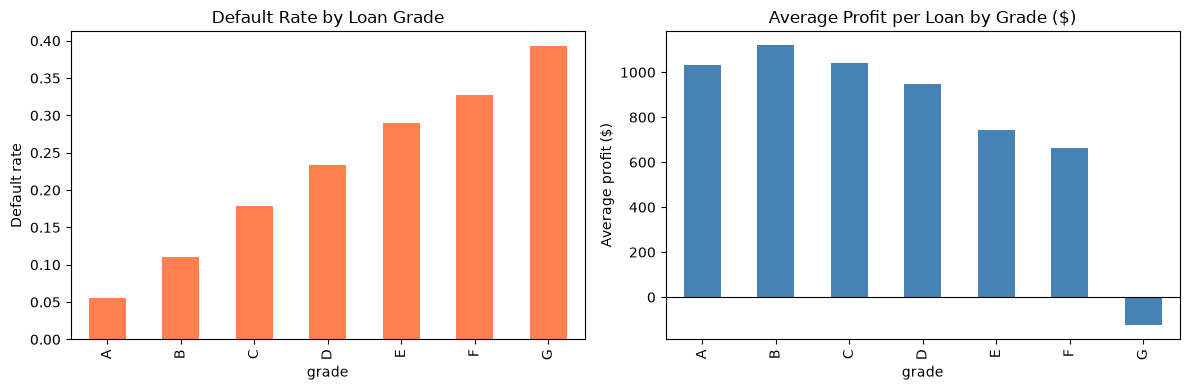

In [35]:
grade_view = df_1.groupby('grade').agg(
    loans=('default', 'size'),
    default_rate=('default', 'mean'),
    avg_profit=('profit', 'mean')).round(3)
print(grade_view)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
grade_view['default_rate'].plot(kind='bar', ax=axes[0], color='coral')
axes[0].set_title('Default Rate by Loan Grade')
axes[0].set_ylabel('Default rate')

grade_view['avg_profit'].plot(kind='bar', ax=axes[1], color='steelblue')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title('Average Profit per Loan by Grade ($)')
axes[1].set_ylabel('Average profit ($)')

plt.tight_layout()
plt.savefig('grade_default_profit.png', dpi=150)
plt.show()

In [37]:
# Paid loans should earn interest, so negative profit here is odd
print("Paid loans with negative profit:", ((df_1['default'] == 0) & (df_1['profit'] < 0)).sum())
print("Defaulted loans with positive profit:", ((df_1['default'] == 1) & (df_1['profit'] > 0)).sum())

Paid loans with negative profit: 5
Defaulted loans with positive profit: 2495


In [38]:
feature_cols = ['loan_amnt', 'int_rate', 'installment', 'grade', 'emp_length',
                'home_ownership', 'annual_inc', 'verification_status', 'purpose',
                'dti', 'delinq_2yrs', 'open_acc', 'pub_rec', 'revol_bal',
                'revol_util', 'total_acc']

model_df = df_1[feature_cols + ['default', 'profit']].copy()

# Grade as a number: A=1 ... G=7
model_df['grade'] = model_df['grade'].map({'A':1,'B':2,'C':3,'D':4,'E':5,'F':6,'G':7})

# Text columns to 0/1 columns
model_df = pd.get_dummies(model_df,
                          columns=['home_ownership', 'verification_status', 'purpose'],
                          drop_first=True, dtype=int)

X = model_df.drop(columns=['default', 'profit'])
y = model_df['default']
profit = model_df['profit']      # kept aside, used only for the money step
print(X.shape)

(150000, 32)


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp, p_train, p_temp = train_test_split(
    X, y, profit, test_size=0.4, random_state=42, stratify=y)

X_val, X_test, y_val, y_test, p_val, p_test = train_test_split(
    X_temp, y_temp, p_temp, test_size=0.5, random_state=42, stratify=y_temp)

print("Sizes:", len(X_train), len(X_val), len(X_test))
print("Default rate:", round(y_train.mean(), 3), round(y_val.mean(), 3), round(y_test.mean(), 3))

Sizes: 90000 30000 30000
Default rate: 0.139 0.139 0.139


In [40]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

model = XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    random_state=42, eval_metric='logloss', n_jobs=-1)
model.fit(X_train, y_train)

val_prob = model.predict_proba(X_val)[:, 1]

print("XGBoost ROC-AUC            :", round(roc_auc_score(y_val, val_prob), 4))
print("XGBoost PR-AUC             :", round(average_precision_score(y_val, val_prob), 4))
print("Interest-rate-only ROC-AUC :", round(roc_auc_score(y_val, X_val['int_rate']), 4))
print("Random PR-AUC (baseline)   :", round(y_val.mean(), 4))

XGBoost ROC-AUC            : 0.6831
XGBoost PR-AUC             : 0.2491
Interest-rate-only ROC-AUC : 0.6592
Random PR-AUC (baseline)   : 0.1394


In [41]:
check = pd.DataFrame({'predicted': val_prob, 'actual': y_val.values})
check['bucket'] = pd.qcut(check['predicted'], 10, labels=False)
print(check.groupby('bucket').agg(
    avg_predicted=('predicted', 'mean'),
    actual_default=('actual', 'mean')).round(3))

        avg_predicted  actual_default
bucket                               
0               0.033           0.028
1               0.058           0.068
2               0.078           0.074
3               0.096           0.095
4               0.115           0.117
5               0.136           0.136
6               0.161           0.166
7               0.190           0.185
8               0.225           0.226
9               0.304           0.300


Approve everyone       : $ 31503678
Best cutoff            : 0.48
Share approved         : 99.9 %
Profit at best cutoff  : $ 31590790
Gain vs approve all    : $ 87112


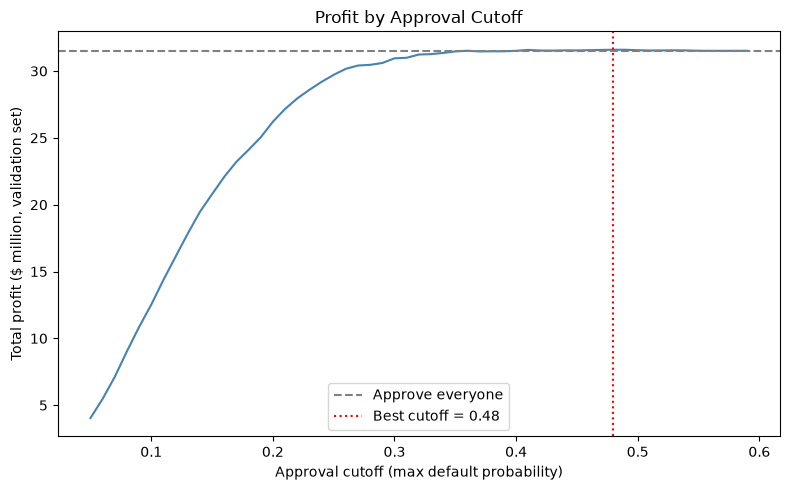

In [42]:
y_v, p_v = y_val.values, p_val.values
cutoffs = np.round(np.arange(0.05, 0.60, 0.01), 2)

rows = []
for c in cutoffs:
    approve = val_prob < c
    rows.append({'cutoff': c,
                 'approved_pct': approve.mean() * 100,
                 'default_rate_approved': y_v[approve].mean(),
                 'total_profit': p_v[approve].sum()})
curve = pd.DataFrame(rows)

approve_all_profit = p_v.sum()
best = curve.loc[curve['total_profit'].idxmax()]
best_cutoff = best['cutoff']

print("Approve everyone       : $", round(approve_all_profit))
print("Best cutoff            :", best_cutoff)
print("Share approved         :", round(best['approved_pct'], 1), "%")
print("Profit at best cutoff  : $", round(best['total_profit']))
print("Gain vs approve all    : $", round(best['total_profit'] - approve_all_profit))

plt.figure(figsize=(8, 5))
plt.plot(curve['cutoff'], curve['total_profit'] / 1e6, color='steelblue')
plt.axhline(approve_all_profit / 1e6, color='gray', linestyle='--', label='Approve everyone')
plt.axvline(best_cutoff, color='red', linestyle=':', label=f'Best cutoff = {best_cutoff}')
plt.xlabel('Approval cutoff (max default probability)')
plt.ylabel('Total profit ($ million, validation set)')
plt.title('Profit by Approval Cutoff')
plt.legend()
plt.tight_layout()
plt.savefig('profit_by_cutoff.png', dpi=150)
plt.show()

In [43]:
# Rule A: best "grade only" rule, chosen on validation (the simple way banks often do it)
grade_val = X_val['grade'].values
best_grade, best_gp = 7, -np.inf
for g in range(1, 8):
    pr = p_v[grade_val <= g].sum()
    if pr > best_gp:
        best_grade, best_gp = g, pr
grade_letter = 'ABCDEFG'[best_grade - 1]
print("Best grade rule: approve grades A to", grade_letter)

# Rule B: approve only if expected profit is positive (uses loan size and interest too)
tr = X_train.copy()
tr['profit'] = p_train.values
tr['default'] = y_train.values
tr['sched_interest'] = tr['installment'] * 36 - tr['loan_amnt']

paid, bad = tr[tr['default'] == 0], tr[tr['default'] == 1]
keep_share = paid['profit'].sum() / paid['sched_interest'].sum()   # share of scheduled interest really earned
loss_ratio = (bad['profit'] / bad['loan_amnt']).mean()             # average result per $1 lent on defaulted loans

def expected_profit(X, prob):
    sched = X['installment'].values * 36 - X['loan_amnt'].values
    return (1 - prob) * keep_share * sched + prob * loss_ratio * X['loan_amnt'].values

print("Share of interest earned on paid loans:", round(keep_share, 3))
print("Average result per $1 on defaulted loans:", round(loss_ratio, 3))

Best grade rule: approve grades A to F
Share of interest earned on paid loans: 0.81
Average result per $1 on defaulted loans: -0.366


In [44]:
test_prob = model.predict_proba(X_test)[:, 1]
p_t = p_test.values

strategies = [
    ('Approve everyone',                    np.ones(len(p_t), dtype=bool)),
    (f'Grade rule (A to {grade_letter})',   X_test['grade'].values <= best_grade),
    (f'Model cutoff (prob < {best_cutoff})', test_prob < best_cutoff),
    ('Expected-profit rule (EV > 0)',       expected_profit(X_test, test_prob) > 0),
]

results = []
for name, a in strategies:
    total = p_t[a].sum()
    results.append({'strategy': name,
                    'approved_%': round(a.mean() * 100, 1),
                    'total_profit': round(total),
                    'profit_per_10k_applicants': round(total / len(p_t) * 10000)})

res = pd.DataFrame(results)
res['gain_vs_approve_all'] = res['profit_per_10k_applicants'] - res.loc[0, 'profit_per_10k_applicants']
print(res.to_string(index=False))

                     strategy  approved_%  total_profit  profit_per_10k_applicants  gain_vs_approve_all
             Approve everyone       100.0      31488510                   10496170                    0
          Grade rule (A to F)        99.9      31508415                   10502805                 6635
   Model cutoff (prob < 0.48)        99.9      31520084                   10506695                10525
Expected-profit rule (EV > 0)        99.4      31573305                   10524435                28265


In [45]:
rng = np.random.default_rng(42)
n = len(p_t)
a_model = test_prob < best_cutoff
a_ev = expected_profit(X_test, test_prob) > 0

g_model, g_ev = [], []
for _ in range(1000):
    idx = rng.integers(0, n, n)          # resample the test loans
    base = p_t[idx].sum()
    g_model.append(p_t[idx][a_model[idx]].sum() - base)
    g_ev.append(p_t[idx][a_ev[idx]].sum() - base)

for name, g in [('Model cutoff', g_model), ('Expected-profit rule', g_ev)]:
    lo, hi = np.percentile(g, [2.5, 97.5])
    print(f"{name}: average gain per 10k applicants ${np.mean(g)/n*10000:,.0f} "
          f"(95% range ${lo/n*10000:,.0f} to ${hi/n*10000:,.0f})")

Model cutoff: average gain per 10k applicants $10,709 (95% range $-8,030 to $30,752)
Expected-profit rule: average gain per 10k applicants $29,293 (95% range $-12,476 to $76,978)


In [46]:
loan_v = X_val['loan_amnt'].values
loan_t = X_test['loan_amnt'].values
grade_t = X_test['grade'].values
ev_t = expected_profit(X_test, test_prob)

rows = []
for k in [0.00, 0.03, 0.05, 0.07]:
    net_v = p_v - k * loan_v
    net_t = p_t - k * loan_t

    # settings chosen on validation only
    best_c = max(cutoffs, key=lambda c: net_v[val_prob < c].sum())
    best_g = max(range(1, 8), key=lambda g: net_v[grade_val <= g].sum())

    base = net_t.sum()
    rules = {'Grade rule': grade_t <= best_g,
             'Model cutoff': test_prob < best_c,
             'Expected-profit rule': (ev_t - k * loan_t) > 0}

    row = {'cost_%_of_loan': int(k * 100),
           'approve_all_per_10k': round(base / n * 10000)}
    for name, a in rules.items():
        row[name + ' gain'] = round((net_t[a].sum() - base) / n * 10000)
        row[name + ' approved%'] = round(a.mean() * 100, 1)
    rows.append(row)

print(pd.DataFrame(rows).T.to_string(header=False))

cost_%_of_loan                         0.0        3.0        5.0        7.0
approve_all_per_10k             10496170.0  6721953.0  4205808.0  1689663.0
Grade rule gain                     6635.0     9804.0    11916.0    37519.0
Grade rule approved%                  99.9       99.9       99.9       95.6
Model cutoff gain                  10525.0    14970.0    40303.0   216681.0
Model cutoff approved%                99.9       98.6       93.0       91.6
Expected-profit rule gain          28265.0    34705.0    97469.0   505129.0
Expected-profit rule approved%        99.4       97.5       92.2       68.3


In [47]:
rng = np.random.default_rng(42)
rows = []
for k in [0.00, 0.03, 0.05, 0.07]:
    net_v = p_v - k * loan_v
    net_t = p_t - k * loan_t
    best_c = max(cutoffs, key=lambda c: net_v[val_prob < c].sum())
    rules = {'Model cutoff': test_prob < best_c,
             'Expected-profit rule': (ev_t - k * loan_t) > 0}

    boot = {name: [] for name in rules}
    bases = []
    for _ in range(1000):
        idx = rng.integers(0, n, n)
        base = net_t[idx].sum()
        bases.append(base)
        for name, a in rules.items():
            boot[name].append(net_t[idx][a[idx]].sum() - base)

    for name, g in boot.items():
        g = np.array(g)
        lo, hi = np.percentile(g, [2.5, 97.5])
        rows.append({'cost_%': int(k * 100), 'rule': name,
                     'gain_per_10k': round(g.mean() / n * 10000),
                     'low': round(lo / n * 10000),
                     'high': round(hi / n * 10000),
                     'gain_%_of_base': round(g.mean() / np.mean(bases) * 100, 1),
                     'clearly_above_zero': lo > 0})

print(pd.DataFrame(rows).to_string(index=False))

 cost_%                 rule  gain_per_10k     low   high  gain_%_of_base  clearly_above_zero
      0         Model cutoff         10709   -8030  30752             0.1               False
      0 Expected-profit rule         29293  -12476  76978             0.3               False
      3         Model cutoff         13592  -57980  86815             0.2               False
      3 Expected-profit rule         35042  -44712 114046             0.5               False
      5         Model cutoff         38279 -103503 185100             0.9               False
      5 Expected-profit rule         96473  -31723 224957             2.3               False
      7         Model cutoff        217867   63708 385697            13.0                True
      7 Expected-profit rule        511743  315541 713003            30.5                True


 cost      gain       low      high  approve_all  approved_pct
  0.0   29554.0   -5709.0   73813.0   10482798.0          99.0
  1.0   46981.0   -1462.0  101301.0    9232505.0          99.0
  2.0   31243.0  -23889.0   86777.0    7975224.0          98.0
  3.0   35739.0  -41172.0  105685.0    6717853.0          98.0
  4.0   46443.0  -43272.0  144006.0    5457070.0          96.0
  5.0   99147.0  -30610.0  247501.0    4207124.0          92.0
  6.0  190939.0   45552.0  340257.0    2956268.0          84.0
  7.0  493890.0  288566.0  667160.0    1700542.0          68.0
  8.0  976055.0  756101.0 1229201.0     448948.0          51.0
  9.0 1639712.0 1368379.0 1917995.0    -817114.0          36.0
 10.0 2474752.0 2158829.0 2769332.0   -2082239.0          25.0


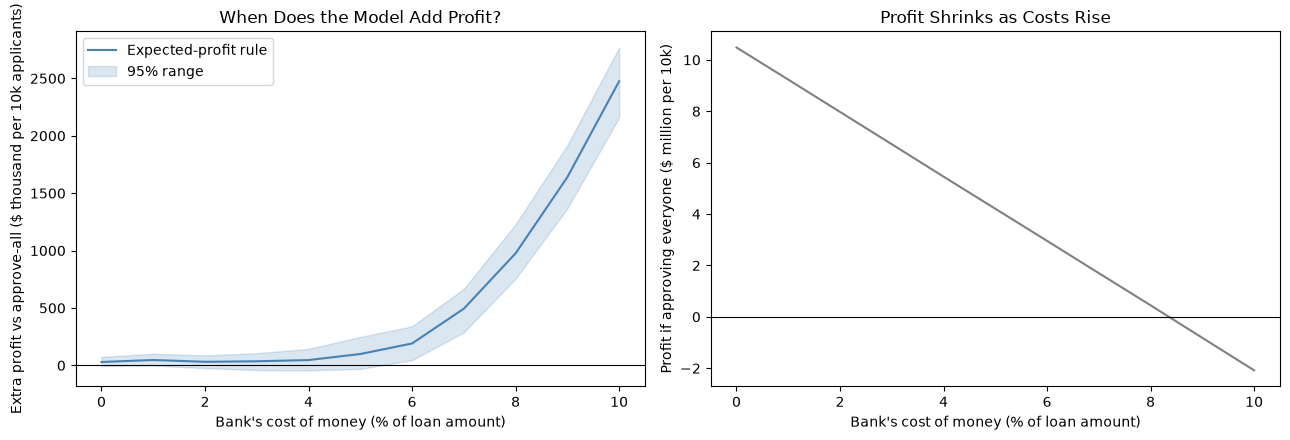

In [48]:
rng = np.random.default_rng(42)
ks = np.round(np.arange(0.00, 0.101, 0.01), 2)
out = []
for k in ks:
    net_t = p_t - k * loan_t
    a = (ev_t - k * loan_t) > 0
    gains, bases = [], []
    for _ in range(300):
        idx = rng.integers(0, n, n)
        base = net_t[idx].sum()
        bases.append(base)
        gains.append(net_t[idx][a[idx]].sum() - base)
    gains = np.array(gains)
    out.append({'cost': k * 100,
                'gain': gains.mean() / n * 10000,
                'low': np.percentile(gains, 2.5) / n * 10000,
                'high': np.percentile(gains, 97.5) / n * 10000,
                'approve_all': np.mean(bases) / n * 10000,
                'approved_pct': a.mean() * 100})
sens = pd.DataFrame(out)
print(sens.round(0).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(sens['cost'], sens['gain'] / 1e3, color='steelblue', label='Expected-profit rule')
axes[0].fill_between(sens['cost'], sens['low'] / 1e3, sens['high'] / 1e3,
                     color='steelblue', alpha=0.2, label='95% range')
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_xlabel("Bank's cost of money (% of loan amount)")
axes[0].set_ylabel('Extra profit vs approve-all ($ thousand per 10k applicants)')
axes[0].set_title('When Does the Model Add Profit?')
axes[0].legend()

axes[1].plot(sens['cost'], sens['approve_all'] / 1e6, color='gray')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_xlabel("Bank's cost of money (% of loan amount)")
axes[1].set_ylabel('Profit if approving everyone ($ million per 10k)')
axes[1].set_title('Profit Shrinks as Costs Rise')

plt.tight_layout()
plt.savefig('gain_vs_cost.png', dpi=150)
plt.show()